Projet AIRBNB - Algorithmes d'apprentissage

-- > l'objectif du projet est de prédire le logarithme du prix des logements Airbnb dont les caractéristiques sont présentés dans l'Excel.


#1. Importation des bibliothèques

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error


## 2. Exploration des données


In [35]:
# 1. Chargement des données
df_train = pd.read_csv('/content/airbnb_train.csv')

# 2. Aperçu global du dataset
print("--- Infos sur le dataset ---\n")
df_train.info()

print("\n--- Aperçu des premières lignes ---\n")
display(df_train.head())

--- Infos sur le dataset ---

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22234 entries, 0 to 22233
Data columns (total 28 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      22234 non-null  int64  
 1   log_price               22234 non-null  float64
 2   property_type           22234 non-null  object 
 3   room_type               22234 non-null  object 
 4   amenities               22234 non-null  object 
 5   accommodates            22234 non-null  int64  
 6   bathrooms               22183 non-null  float64
 7   bed_type                22234 non-null  object 
 8   cancellation_policy     22234 non-null  object 
 9   cleaning_fee            22234 non-null  bool   
 10  city                    22234 non-null  object 
 11  description             22234 non-null  object 
 12  first_review            17509 non-null  object 
 13  host_has_profile_pic    22178 non-null  object 
 14  host_ide

,id,log_price,property_type,room_type,amenities,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,...,last_review,latitude,longitude,name,neighbourhood,number_of_reviews,review_scores_rating,zipcode,bedrooms,beds
0,5708593,4.317488,House,Private room,"{TV,""Wireless Internet"",Kitchen,""Free parking ...",3,1.0,Real Bed,flexible,False,...,NaN,33.782712,-118.134410,Island style Spa Studio,Long Beach,0,NaN,90804,0.0,2.0
1,14483613,4.007333,House,Private room,"{""Wireless Internet"",""Air conditioning"",Kitche...",4,2.0,Real Bed,strict,False,...,2017-09-17,40.705468,-73.909439,"Beautiful and Simple Room W/2 Beds, 25 Mins to...",Ridgewood,38,86.0,11385,1.0,2.0
2,10412649,7.090077,Apartment,Entire home/apt,"{TV,""Wireless Internet"",""Air conditioning"",Kit...",6,2.0,Real Bed,flexible,False,...,NaN,38.917537,-77.031651,2br/2ba luxury condo perfect for infant / toddler,U Street Corridor,0,NaN,20009,2.0,2.0
3,17954362,3.555348,House,Private room,"{TV,""Cable TV"",Internet,""Wireless Internet"",""A...",1,1.0,Real Bed,flexible,True,...,2017-09-29,40.736001,-73.924248,Manhattan view from Queens. Lovely single room .,Sunnyside,19,96.0,11104,1.0,1.0
4,9969781,5.480639,House,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",Ki...",4,1.0,Real Bed,moderate,True,...,2017-08-28,37.744896,-122.430665,Zen Captured Noe Valley House,Noe Valley,15,96.0,94131,2.0,2.0


## 3. Visualisation des données


## 3.1 Visualisation de la variable cible (log_price)


Justification : avant de prédire la variable, on peut regarder sa forme pour avoir une meilleure visualisation.

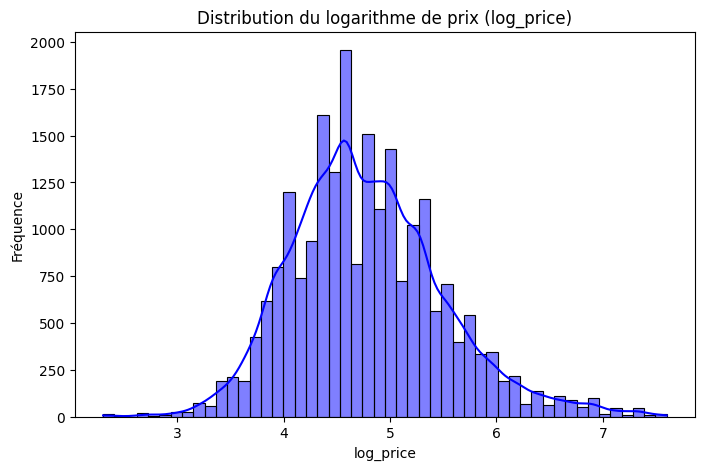

In [36]:
plt.figure(figsize=(8, 5))
sns.histplot(df_train['log_price'], bins=50, kde=True, color='blue')
plt.title('Distribution du logarithme de prix (log_price)')
plt.xlabel('log_price')
plt.ylabel('Fréquence')
plt.show()

On a une belle courbe centrée, car les valeurs extrêmes (les prix exorbitants ou minuscules) ont déjà été "écrasées" grâce au passage au logarithme.

## 3.2 Matrice de corrélation pour les variables numériques



Justification : ce graphique permet d'identifier d'un seul coup d'œil quelles variables numériques ont la plus forte relation linéaire avec le prix. Il permet aussi de repérer la colinéarité potentielle (probable) entre des variables.

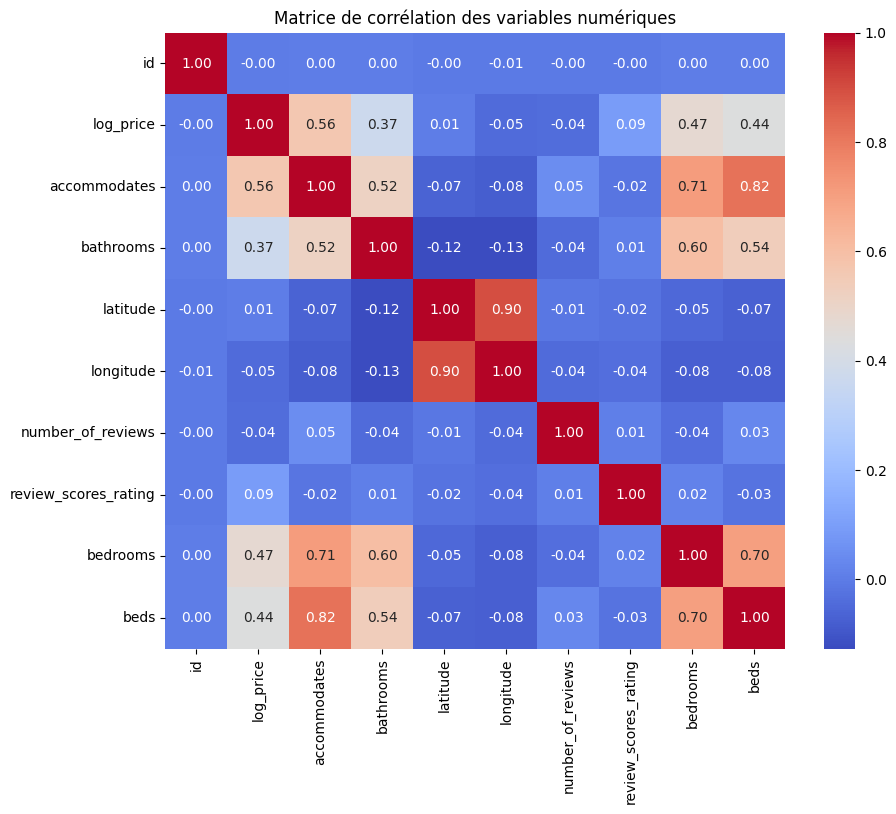

In [37]:
plt.figure(figsize=(10, 8))
numeric_cols = df_train.select_dtypes(include=['float64', 'int64']).columns
sns.heatmap(df_train[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matrice de corrélation des variables numériques')
plt.show()

On observe que "accommodates" (capacité) est fortement corrélée au prix (0.56), suivie par "bedrooms" (0.47) et "beds" (0.44).


## 3.3 Impact du type de chambre sur le prix (boxplot)


Justification : vérifier si une chambre privée est vraiment moins chère qu'un appart entier.


/tmp/ipykernel_5279/3462056255.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='room_type', y='log_price', data=df_train, palette='Set2')


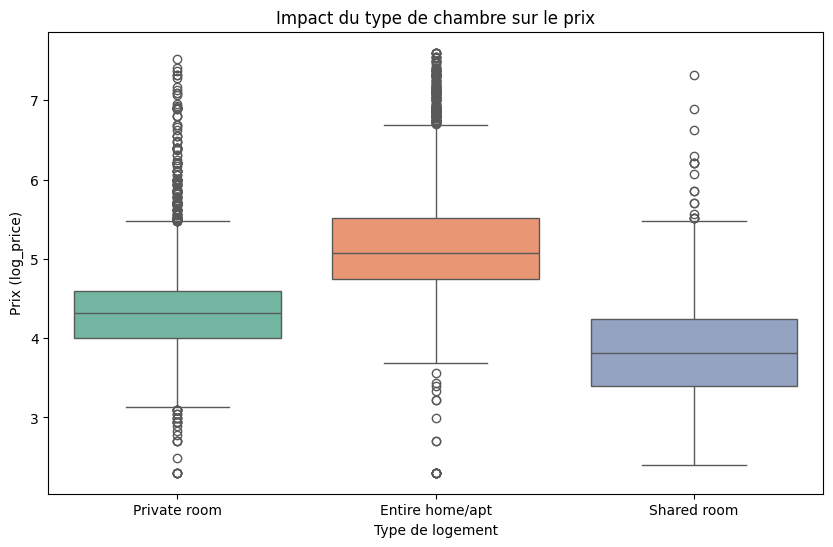

In [38]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='room_type', y='log_price', data=df_train, palette='Set2')
plt.title('Impact du type de chambre sur le prix')
plt.xlabel('Type de logement')
plt.ylabel('Prix (log_price)')
plt.show()


Sans surprise, on constate que la location d'un logement entier ("Entire home/apt") est significativement plus chère qu'une chambre privée ou partagée : le rectangle est plus "haut" que les deux autres.


## 3.4 Les villes les plus chères (violin plot)


Justification : comprendre la disparité des prix selon les grandes villes américaines.


/tmp/ipykernel_5279/3974378466.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='city', y='log_price', data=df_train, palette='muted')


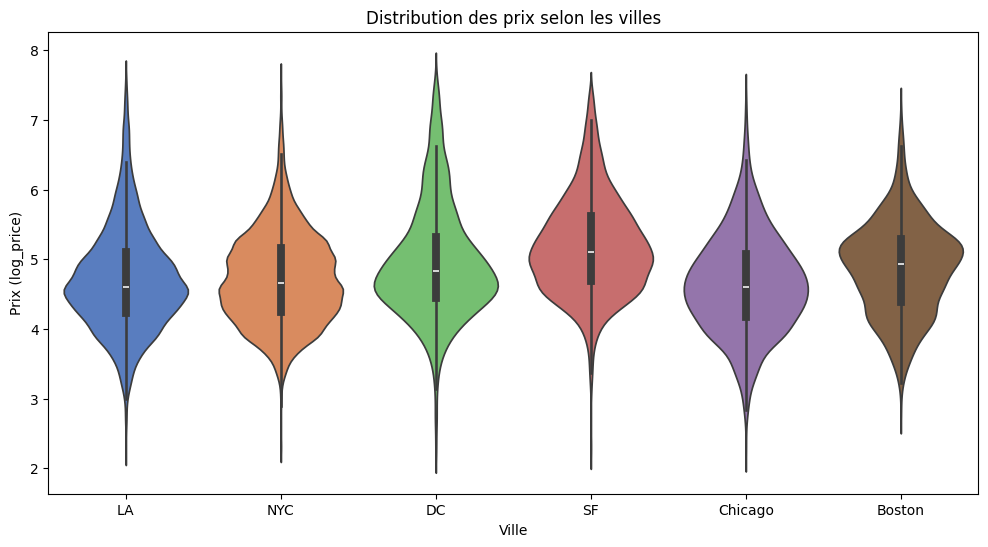

In [39]:
plt.figure(figsize=(12, 6))
sns.violinplot(x='city', y='log_price', data=df_train, palette='muted')
plt.title('Distribution des prix selon les villes')
plt.xlabel('Ville')
plt.ylabel('Prix (log_price)')
plt.show()

On constate que San Francisco ("SF") se démarque avec un prix médian plus élevé que les autres villes, indiquant que la localisation géographique sera une variable intéressante à prendre en compte.


## 3.5 Capacité d'accueil vs Prix (barplot avec intervalle de confiance)


Justification : confirmer la forte corrélation vue dans la matrice.


/tmp/ipykernel_5279/2657554719.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='accommodates', y='log_price', data=df_train, palette='Blues_d')


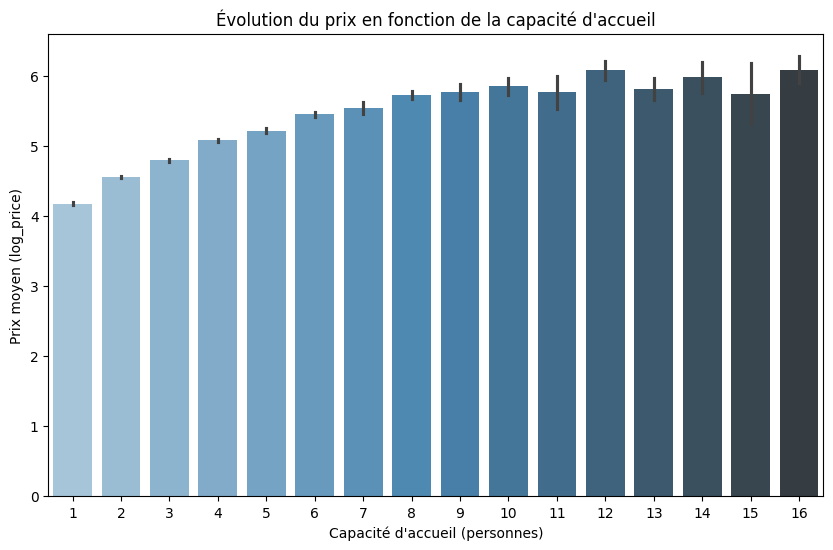

In [40]:
plt.figure(figsize=(10, 6))
sns.barplot(x='accommodates', y='log_price', data=df_train, palette='Blues_d')
plt.title("Évolution du prix en fonction de la capacité d'accueil")
plt.xlabel("Capacité d'accueil (personnes)")
plt.ylabel('Prix moyen (log_price)')
plt.show()

On constate que la relation est quasi-linéaire : plus on peut accueillir de personnes, plus le prix augmente. Cela paraît finalement assez intuitif et confirme la corrélation entre ces deux variables.

## 3.6 Carte des prix sur un échantillon


Justification : visualiser si l'emplacement (centre-ville ou banlieue) impacte le prix.


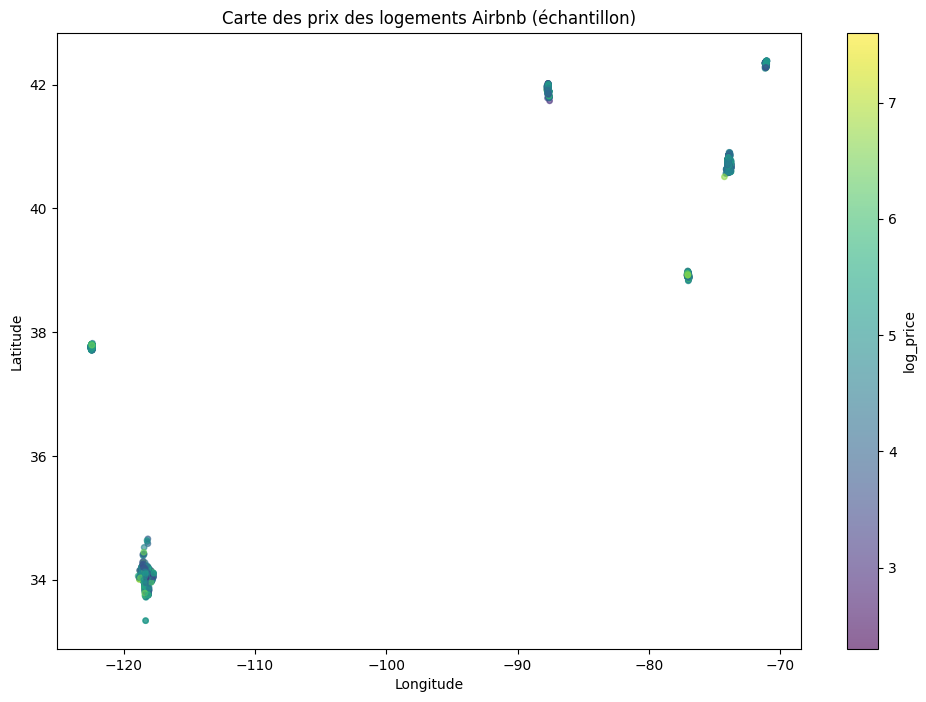

In [41]:
sample_df = df_train.sample(n=5000, random_state=42) # on prend un échantillon pour que le graphique soit lisible
plt.figure(figsize=(12, 8))
scatter = plt.scatter(sample_df['longitude'], sample_df['latitude'],
                      c=sample_df['log_price'], cmap='viridis',
                      alpha=0.6, s=15) # on utilise la longitude et latitude pour dessiner la carte des logements
plt.colorbar(scatter, label='log_price')
plt.title('Carte des prix des logements Airbnb (échantillon)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

On distingue très bien les "clusters" de prix élevés sur la côte californienne (SF, LA) et sur la côte Est (NYC, Boston), ce qui confirme l'importance de la variable "city" et des coordonnées GPS. Pour reconnaître les villes citées, il faut évidemment passer par leur localisation (latitude, longitude).

# 4. Nettoyage, remplissage et encodage des données


In [42]:
def nettoyer_donnees(df, is_train=True):
    df_clean = df.copy()

    # 1. Remplissage des valeurs manquantes par la médiane
    df_clean['bathrooms'] = df_clean['bathrooms'].fillna(df_clean['bathrooms'].median())
    df_clean['bedrooms'] = df_clean['bedrooms'].fillna(df_clean['bedrooms'].median())
    df_clean['beds'] = df_clean['beds'].fillna(df_clean['beds'].median())

    # 2. Conversion booléen -> int
    df_clean['cleaning_fee'] = df_clean['cleaning_fee'].astype(int)

    # 3. Comptage des équipements
    df_clean['nb_amenities'] = df_clean['amenities'].apply(lambda x: len(x.split(',')) if isinstance(x, str) else 0)

    # 4. Suppression des colonnes inutilisées
    cols_to_drop = [
        'id', 'amenities', 'bed_type', 'description', 'first_review',
        'host_has_profile_pic', 'host_identity_verified', 'host_response_rate',
        'host_since', 'instant_bookable', 'last_review', 'name',
        'neighbourhood', 'zipcode', 'review_scores_rating', 'Unnamed: 0'
    ]
    df_clean = df_clean.drop(columns=cols_to_drop, errors='ignore') # errors='ignore' permet de ne pas planter si
    # la colonne 'id' n'est pas nommée pareil dans le test

    # 5. Encodage One-Hot pour tranformer les variables textuelles en numériques (pour l'exploitabilité)
    cols_to_encode = ['room_type', 'cancellation_policy', 'property_type', 'city']
    df_clean = pd.get_dummies(df_clean, columns=cols_to_encode, drop_first=True)

    return df_clean

# On applique la fonction sur nos données d'entraînement
df_train_clean = nettoyer_donnees(df_train)
print(f"Nombre de dimensions après nettoyage du dataset: {df_train_clean.shape}")

Nombre de dimensions après nettoyage du dataset: (22234, 51)


On a supprimé les colonnes pas forcément utiles dans le jeu de données: corrélées à aucune autre(s), contenant du texte peu intéressant (comme "description"), étant des variables booléennes("instant_bookable")...etc. On affiche ensuite le nombre de domensions après nettoyage, qui est de (22234, 51). Le nombre de colonnes est passé de 28 à 51, ce qui prouve que l'encodage a bien marché.


# 5. Comparaison des modèles : régression linéaire vs arbre de déceision


In [43]:
# On sépare X (features) et y (target)
X = df_train_clean.drop('log_price', axis=1)
y = df_train_clean['log_price']

# Séparation 80% / 20% (comme demandé dasn le sujet)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

## 5.1 MODELE 1 : Base (régression linéaire)


In [44]:
baseline_model = LinearRegression()
baseline_model.fit(X_train, y_train)
baseline_preds = baseline_model.predict(X_val)
baseline_rmse = np.sqrt(mean_squared_error(y_val, baseline_preds))
print(f"Score RMSE baseline (régression linéaire) : {baseline_rmse:.4f}")


Score RMSE baseline (régression linéaire) : 0.4737


## - MODELE 2 : Random forest (basé sur l'arbre de décision)


In [45]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_val)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_preds))
print(f"Score RMSE random forest : {rf_rmse:.4f}")

Score RMSE random forest : 0.4193


On constate que la régression linéaire (baseline) obtient un score très correct
(0.4737) mais le random forest s'avère meilleur (0.4193).
Comme vu au CM5, les
arbres de décision permettent de capturer des relations non-linéaires
complexes entre les variables comme l'interaction entre une ville chère et la
capacité d'accueil, que la régression linéaire ne peut pas modéliser directement.
C'est donc le random forest qu'on utilisera pour la prédiction finale.

#6. Prédiction sur le test et génération du CSV


On entraine notre meilleur modèle sur 100% des données d'entraînement (fichier airbnb_test.csv fourni) pour garantir sa robustesse, on le nettoie, puis on prédit les valeurs sur les données.

In [46]:
# 1. Entraînement sur 100% des données d'entraînement
print("Entraînement du modèle final sur l'intégralité des données...")
rf_model.fit(X, y)

# 2. Chargement des données de test
df_test = pd.read_csv('airbnb_test.csv')
test_ids = df_test['Unnamed: 0']

# 3. Nettoyage du test avec notre fonction
df_test_clean = nettoyer_donnees(df_test, is_train=False)

# 4. Alignement strict des colonnes
X_test = df_test_clean.reindex(columns=X.columns, fill_value=0)

# 5. Prédiction finale avec le modèle random forest (meilleur que la régression linéaire)
print("Prédiction en cours...")
predictions_finales = rf_model.predict(X_test)

# 6. Création du fichier d'export
soumission = pd.DataFrame({
    'id': test_ids,
    'log_price': predictions_finales
})

soumission.to_csv('prediction_finale_airbnb_Jeanne_Faizan.csv', index=False)
print("=> Fichier 'prediction_finale_airbnb_Jeanne_Faizan.csv' généré avec succès.")

Entraînement du modèle final sur l'intégralité des données...
Prédiction en cours...
=> Fichier 'prediction_finale_airbnb_Jeanne_Faizan.csv' généré avec succès.


Le fichier est généré. Il contient 51 877 lignes et les deux colonnes attendues ("id" et "log_price"). Les valeurs prédites tournent autour de 4.0 à 6.0, ce qui est totalement cohérent pour un logarithme de prix.